# Implementation: superpixels, GMM and saved RF classification
Run cells in order using **Python (crystal_seg)** from `implement/` or the project root. Drawing code is included in this notebook. The first part explains SLIC and a **2D educational GMM** on one cropped preview (maximum side 640 pixels). The RF part processes **eight full-resolution cropped images from `data/mag500/old/pl09`**, using the actual production feature functions and saved `rf_step1.pkl`.

The 2D GMM allows Gaussian ellipses to be drawn. Production RF grouping instead uses up to **15 PCA axes** and the production GMM initialization. Cluster IDs are local to each image and do not identify RF classes. Tutorial outputs are isolated under `implement/outputs/tutorial_001/`; saved models and main-run results are unchanged.

After RF voting, sections 10–12 show eight-image grids per RF class and per direct additional-GMM subclass. Additional GMM assigns each superpixel independently of original pre-RF GMM clusters. A separate final check shows the same assignments one image at a time.

## 1. Paths, input images and the archived manual GMM count
The pre-RF GMM call in `archive/superpixel_RF_GMM_implement.ipynb` (sixth cell, `run_gmm_per_image(...)`) explicitly sets `n_components=3` for all images. The function's default of 4 is overridden by that call. No per-image pre-RF count mapping was found in that implementation archive; its later class-specific configurations belong to **additional GMM after RF**.

`training/data/tables/gmm_settings.csv` preserves per-image training settings; of these eight images, it contains `20260806_140636` and `20260806_140719`, both with 3 components. It does not provide counts for the other six. Therefore this tutorial uses the implementation archive's explicit common count for all eight, without inventing missing per-image settings.

`PRE_GMM_COMPONENTS` below is the shared manual setting for both the single-image 2D demo and the production pre-RF GMM. Change it here and rerun downstream cells to compare another count. The PCA dimensions and fitting initialization still differ between the educational demo and production.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import io
import joblib
from IPython.display import display

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "implement_tutorial.ipynb").is_file(): WORK_DIR /= "implement"
if not (WORK_DIR / "implement_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from implement/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))
sys.path.insert(0, str(WORK_DIR))
from crystal_pipeline import _natural_key

IMAGE_DIR = PROJECT_ROOT / "data/mag500/old/pl09"
RF_IMAGE_PATHS = sorted(IMAGE_DIR.glob("*.jpg"), key=_natural_key)[:8]
if len(RF_IMAGE_PATHS) != 8:
    raise ValueError(f"Expected at least eight JPG images in {IMAGE_DIR}.")
IMAGE_PATH = next((path for path in RF_IMAGE_PATHS if path.name.endswith("140719.jpg")), RF_IMAGE_PATHS[0])
OUTPUT_DIR = WORK_DIR / "outputs" / "tutorial_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Image: {IMAGE_PATH}\nTutorial outputs: {OUTPUT_DIR}")

# The saved RF was trained with archived training features and this Lab reference.
REFERENCE_PATH = WORK_DIR / "data" / "models" / "rf_step1.pkl"

# Archived implementation, sixth cell: run_gmm_per_image(..., n_components=3).
PRE_GMM_COMPONENTS = 3
print(f"Archived manual pre-RF GMM count: {PRE_GMM_COMPONENTS} (all eight images)")
display(pd.DataFrame({"name": [path.stem for path in RF_IMAGE_PATHS],
                      "n_components": PRE_GMM_COMPONENTS}))


Image: /home/kmanabe2403/dune/data/mag500/old/pl09/20260806_140719.jpg
Tutorial outputs: /home/kmanabe2403/dune/implement/outputs/tutorial_001
Archived manual pre-RF GMM count: 3 (all eight images)
              name  n_components
0  20260806_140636             3
1  20260806_140719             3
2  20260806_140810             3
3  20260806_140854             3
4  20260806_140941             3
5  20260806_141042             3
6  20260806_141133             3
7  20260806_141208             3


## 2. Crop
Black frames mark the actual image edges, including the original white border. The red rectangle marks the retained crop. This comparison keeps the original resolution; only the subsequent educational GMM uses a resized preview. The RF section below uses the full-resolution crop.

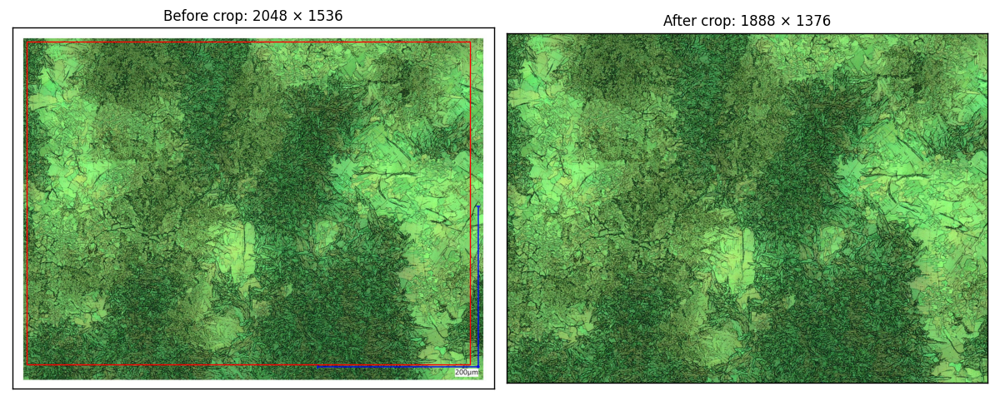

Analysis preview: (466, 640, 3); main-pipeline images are unchanged.


In [2]:
original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = {"top": 60, "bottom": 100, "left": 60, "right": 100}
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"]-.5, crop["top"]-.5), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title(f"Before crop: {original.shape[1]} × {original.shape[0]}")
axes[1].imshow(image)
axes[1].set_title(f"After crop: {image.shape[1]} × {image.shape[0]}")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=120)
plt.show()
plt.close(fig)
del original

from skimage.transform import resize
MAX_SIDE = 640  # Use None for full-resolution analysis (slower and more memory-intensive).
if MAX_SIDE is not None and max(image.shape[:2]) > MAX_SIDE:
    shape = tuple(max(1, round(v * MAX_SIDE / max(image.shape[:2]))) for v in image.shape[:2])
    image = resize(image, shape, preserve_range=True, anti_aliasing=True).round().astype(np.uint8)
print(f'Analysis preview: {image.shape}; main-pipeline images are unchanged.')


## 3. Superpixels
Each superpixel groups nearby pixels. Thin red lines show their boundaries. This calls the same SLIC preprocessing as the main pipeline, including its original color handling.

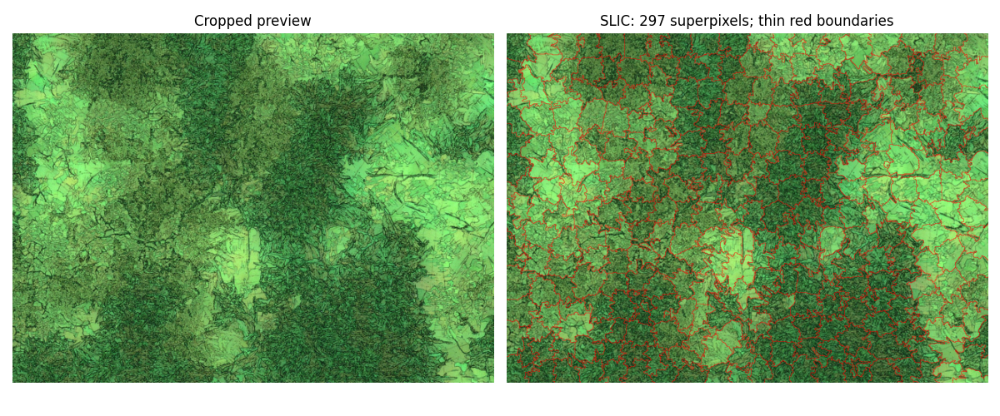

In [3]:
from skimage.color import rgb2lab
from skimage.segmentation import slic, mark_boundaries

# Same SLIC call/color handling as production, applied to the smaller tutorial preview.
lab = rgb2lab(image)
segments = slic(lab, n_segments=300, compactness=10.0, sigma=1, start_label=1)
sp_labels = np.unique(segments)
means = np.array([lab[segments == label].mean(axis=0) for label in sp_labels], dtype=np.float32)
PREPROCESS_DIR = OUTPUT_DIR / "preprocessing"
PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)
np.save(PREPROCESS_DIR / "image.npy", image)
np.save(PREPROCESS_DIR / "segments.npy", segments)
np.savez(PREPROCESS_DIR / "lab_means.npz", labels=sp_labels, lab_means=means)
del lab
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Cropped preview")
axes[1].imshow(np.clip(mark_boundaries(image, segments, color=(1, 0, 0), mode="subpixel"), 0, 1))
axes[1].set_title(f"SLIC: {len(sp_labels)} superpixels; thin red boundaries")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_superpixels.png", dpi=120)
plt.show()
plt.close(fig)


## 4. Real features and two PCA axes
Use the same 18 superpixel feature functions and fixed Lab reference as production. PCA reduces standardized features to two axes for drawing the GMM; the printed variance fraction reports how much feature variation remains. No reference or RF model is trained on this image.

The shared feature function uses the archived training calculation used by the saved RF: weighted `rgb2gray`, and pixel-level float32 Lab correction before superpixel means. The Lab reference comes from this RF model, retaining its saved precision.

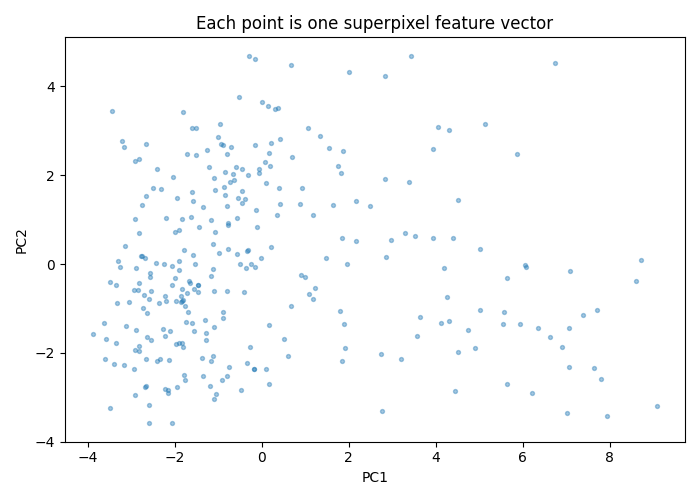

297 superpixels × 18 features; same feature functions as the main pipeline.
PCA variance retained: 68.0%


In [4]:
from crystal_features import calculate_image_features, FEATURE_NAMES

with np.load(PREPROCESS_DIR / "lab_means.npz") as saved:
    sp_labels, means = saved["labels"], saved["lab_means"]
reference = np.asarray(joblib.load(REFERENCE_PATH)["reference_mean"])
# Reproduce archived training's float64 image reference before pixel-level correction.
preview_lab = rgb2lab(image)
means = np.array([preview_lab[segments == label].mean(axis=0) for label in sp_labels])
del preview_lab
correction = reference - means.mean(axis=0)
corrected_path = OUTPUT_DIR / "corrected_lab.npz"
np.savez(corrected_path, labels=sp_labels, lab_means=means + correction, correction=correction)
sp_labels, features = calculate_image_features(PREPROCESS_DIR, corrected_path)
feature_names = FEATURE_NAMES
np.savez(OUTPUT_DIR / "features.npz", labels=sp_labels, features=features, feature_names=feature_names)
print(f"{len(features)} superpixels × {features.shape[1]} features; same feature functions as the main pipeline.")
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
pca = PCA(n_components=2, random_state=0)
X = pca.fit_transform(scaler.fit_transform(features))
print(f"PCA variance retained: {pca.explained_variance_ratio_.sum():.1%}")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], s=8, alpha=.4)
ax.set(xlabel="PC1", ylabel="PC2", title="Each point is one superpixel feature vector")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_pca.png", dpi=150)
plt.show()
plt.close(fig)


## 5. EM updates, Gaussian ellipses and fitting progress
The same model continues from initialization (0 EM updates) through 5 updates to convergence. Each E step calculates soft responsibilities; each M step updates centers, covariances and mixture weights. Colors identify components; crosses mark centers. Ellipses show **2-standard-deviation contours**, not confidence intervals. Their size describes covariance; thicker, more opaque outlines indicate larger mixture weights on the same scale across snapshots.

The second figure shows mean log likelihood on the fitted image. This measures fit, not accuracy on new images. If convergence is not reached in 500 updates, the final title reports the iteration limit.

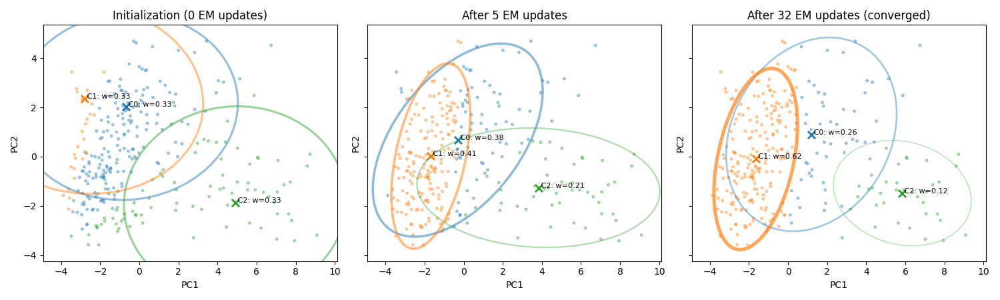

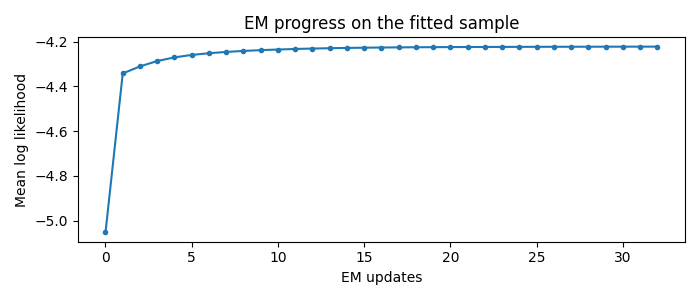

Final iteration: 32; converged: True; mean log likelihood: -4.2221


In [5]:
from copy import deepcopy
import warnings
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning

N_CLUSTERS = PRE_GMM_COMPONENTS  # Share the archived manual count with pre-RF GMM.
# Initialize once, then continue the SAME model one EM update at a time.
initial_means = X[np.random.default_rng(0).choice(len(X), N_CLUSTERS, replace=False)]
gmm = GaussianMixture(N_CLUSTERS, covariance_type="full", random_state=0, n_init=1, init_params="random",
                      means_init=initial_means, weights_init=np.full(N_CLUSTERS, 1 / N_CLUSTERS),
                      reg_covar=1e-5,
                      warm_start=True, max_iter=0, tol=1e-4)
gmm.fit(X)  # Initialization only: zero EM updates.
snapshots = [(0, deepcopy(gmm))]
log_likelihood = [gmm.score(X)]
gmm.max_iter = 1
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)  # One-update fits are intentionally unfinished.
    for iteration in range(1, 501):
        gmm.fit(X)
        log_likelihood.append(gmm.score(X))
        if iteration == 5: snapshots.append((iteration, deepcopy(gmm)))
        if iteration > 5 and gmm.converged_: break
snapshots.append((iteration, deepcopy(gmm)))
print(f"Final iteration: {iteration}; converged: {gmm.converged_}; mean log likelihood: {gmm.score(X):.4f}")
from matplotlib.patches import Ellipse

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
colors = plt.cm.tab10(np.arange(N_CLUSTERS))
for ax, (step, model) in zip(axes, snapshots):
    labels = model.predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=colors[labels], s=7, alpha=.35, rasterized=True)
    for k, (mean, covariance, weight) in enumerate(zip(model.means_, model.covariances_, model.weights_)):
        values, vectors = np.linalg.eigh(covariance)
        order = np.argsort(values)[::-1]
        values, vectors = values[order], vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        strength = weight
        ax.add_patch(Ellipse(mean, 4 * np.sqrt(values[0]), 4 * np.sqrt(values[1]), angle=angle,
                             fill=False, edgecolor=colors[k], linewidth=.6 + 5 * strength, alpha=.2 + .8 * strength))
        ax.scatter(*mean, marker="x", s=65, color=colors[k], linewidth=2)
        ax.annotate(f" C{k}: w={weight:.2f}", mean, fontsize=8)
    title = "Initialization (0 EM updates)" if step == 0 else f"After {step} EM updates"
    if step == snapshots[-1][0]: title += " (converged)" if model.converged_ else " (iteration limit)"
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
# Fix one view across snapshots; ellipses can extend outside the observed-data range.
low, high = X.min(axis=0), X.max(axis=0)
pad = np.maximum((high - low) * .08, .1)
axes[0].set(xlim=(low[0]-pad[0], high[0]+pad[0]), ylim=(low[1]-pad[1], high[1]+pad[1]))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_em_steps.png", dpi=150)
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(len(log_likelihood)), log_likelihood, marker=".")
ax.set(xlabel="EM updates", ylabel="Mean log likelihood", title="EM progress on the fitted sample")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_em_progress.png", dpi=120)
plt.show()
plt.close(fig)


## 6. Final 2D demo and pixel-area fractions
The top row shows the cropped preview and a bar chart of assigned pixel-area fractions. The bottom row shows only the original-color superpixels assigned to each GMM component, with all other pixels white. Each superpixel contributes its actual number of pixels, so these fractions need not equal GMM mixture weights. The three panels are components of this demonstration, not physical crystal classes.

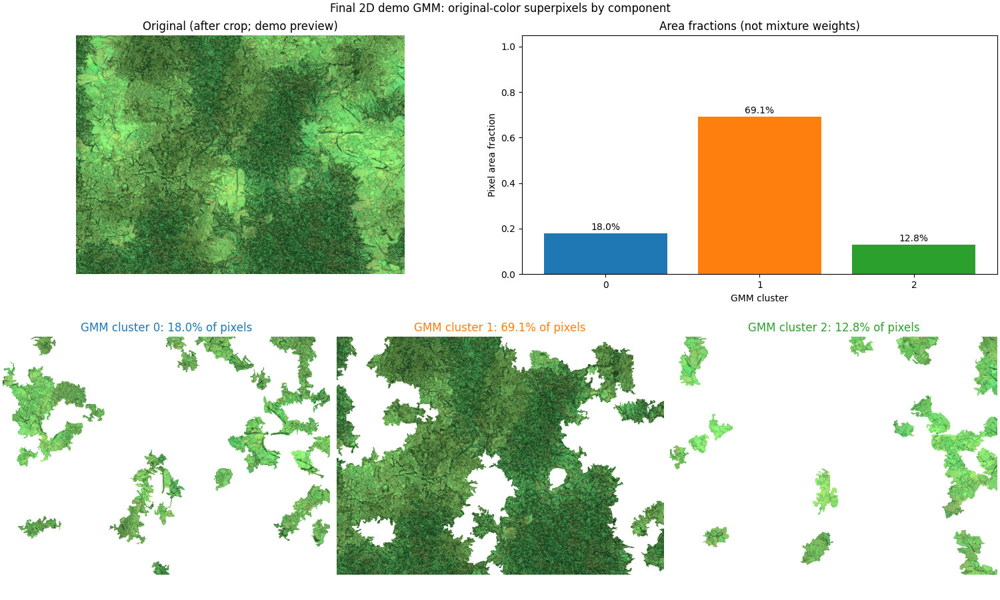

In [6]:
probabilities = gmm.predict_proba(X)
cluster_ids = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
indices = np.searchsorted(sp_labels, segments)
cluster_map, confidence_map = cluster_ids[indices], confidence[indices]
counts = np.bincount(cluster_map.ravel(), minlength=N_CLUSTERS)
area = counts / counts.sum()

fig = plt.figure(figsize=(15, 9), layout="constrained")
top, bottom = fig.subfigures(2, 1)
original_ax, area_ax = top.subplots(1, 2)
original_ax.imshow(image)
original_ax.set_title("Original (after crop; demo preview)")
original_ax.axis("off")
area_ax.bar(np.arange(N_CLUSTERS), area, color=colors)
area_ax.set(xlabel="GMM cluster", ylabel="Pixel area fraction", xticks=np.arange(N_CLUSTERS),
            ylim=(0, 1.05), title="Area fractions (not mixture weights)")
for k, value in enumerate(area):
    area_ax.text(k, value + .015, f"{value:.1%}", ha="center")
for k, ax in enumerate(np.atleast_1d(bottom.subplots(1, N_CLUSTERS))):
    view = np.full_like(image, 255)
    mask = cluster_map == k
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(f"GMM cluster {k}: {area[k]:.1%} of pixels", color=colors[k])
    ax.axis("off")
fig.suptitle("Final 2D demo GMM: original-color superpixels by component")
fig.savefig(OUTPUT_DIR / "05_maps_and_areas.png", dpi=150)
plt.show()
plt.close(fig)
np.savez_compressed(OUTPUT_DIR / "demo_maps.npz", cluster_map=cluster_map,
                    confidence_map=confidence_map, area=area)


## 7. Saved first-stage RF: eight full-resolution images
This section uses the eight naturally sorted JPGs in `old/pl09`. It calls production preprocessing (300 SLIC targets, compactness 10), color correction and all 18 original features, then production GMM (`PRE_GMM_COMPONENTS` components from the archived manual setting, up to 15 PCs, 5 initializations). **No preview resizing is used here.** Images are processed one at a time and intermediate arrays are stored in a separate `rf_stage1` tutorial run. This cell takes longer than the 2D demonstration.

The saved RF receives original features in its saved feature order, not PCA coordinates. For each GMM cluster, each valid member superpixel gets one RF vote; the most frequent RF label is assigned to all its members. Votes count superpixels, not pixels, and use the production tie-breaking rule. The 0.90 GMM confidence threshold is saved as a diagnostic; production majority voting includes all finite-feature GMM members, not only those above that threshold.

Only **stage 1** is demonstrated: no second/third-stage RF routing or manual correction is applied. Labels below are the saved model's raw IDs (0–4), exactly as returned by production; its `name_map` associates them with training group names (1–5).

This RF run uses archived-training feature arithmetic and the Lab reference stored in `rf_step1.pkl`, in the separate `rf_stage1_legacy_training/` directory. Earlier results under `rf_stage1/` are retained for the controlled comparison in Appendix C.

In [7]:
from crystal_pipeline import prepare_run, load_run
from crystal_preprocessing import run_preprocessing, run_color_correction
from crystal_features import run_feature_extraction
from crystal_gmm import run_gmm
from crystal_rf import classify_image, majority_vote

RF_RUN_DIR = OUTPUT_DIR / "rf_stage1_legacy_training"
RF_CONFIG = {
    "data_dir": "data/mag500", "target_plates": {"old": ["pl09"]}, "images_per_plate": 8,
    "crop": crop, "n_segments": 300, "compactness": 10.0,
}
prepare_run(PROJECT_ROOT, RF_RUN_DIR, RF_CONFIG)
_, rf_records = load_run(RF_RUN_DIR)
assert [PROJECT_ROOT / record["path"] for record in rf_records] == RF_IMAGE_PATHS
run_preprocessing(PROJECT_ROOT, RF_RUN_DIR)
run_color_correction(RF_RUN_DIR, REFERENCE_PATH)
run_feature_extraction(RF_RUN_DIR)
gmm_settings = pd.DataFrame({"image_id": [r["image_id"] for r in rf_records],
                             "name": [r["name"] for r in rf_records],
                             "n_components": PRE_GMM_COMPONENTS})
gmm_settings.to_csv(RF_RUN_DIR / "metadata/pre_gmm_settings.csv", index=False)
run_gmm(RF_RUN_DIR, n_components=PRE_GMM_COMPONENTS, pca_components=15, probability_cut=.90)

rf_package = joblib.load(WORK_DIR / "data/models/rf_step1.pkl")
rf_model = rf_package["model"]
rf_feature_names = list(rf_package["feature_names"])
if rf_model.n_features_in_ != len(rf_feature_names):
    raise ValueError("Saved RF feature count does not match its feature names.")
rf_classes = [str(label) for label in rf_model.classes_]
rf_names = {str(key): str(value) for key, value in rf_package.get("name_map", {}).items()}
RF_RESULT_DIR = RF_RUN_DIR / "rf"
RF_RESULT_DIR.mkdir(parents=True, exist_ok=True)
vote_rows, cluster_rows = [], []
for record in rf_records:
    name = f"image_{record['image_id']:04d}"
    # Reuse production classification; consume stage1 results only.
    output, _, rows = classify_image(RF_RUN_DIR, record, [{"all": rf_model}, {}, {}], rf_feature_names)
    with np.load(RF_RUN_DIR / "features" / f"{name}.npz", allow_pickle=False) as saved:
        columns = saved["feature_names"].tolist()
        rf_X = saved["features"][:, [columns.index(feature) for feature in rf_feature_names]]
    probability = rf_model.predict_proba(rf_X)
    individual = rf_model.classes_[probability.argmax(axis=1)].astype(str)
    with np.load(RF_RUN_DIR / "gmm" / f"{name}.npz", allow_pickle=False) as saved:
        valid, groups = saved["valid_indices"], saved["cluster_labels"]
    for row in rows:
        members = valid[groups == row["cluster_id"]]
        winner, majority = majority_vote(individual[members])
        assert winner == row["stage1_label"]
        assert majority == row["stage1_majority"]
        assert np.all(output["stage1_labels"][members] == winner)
        cluster_rows.append({"image_id": record["image_id"], "name": record["name"],
                             **{key: row[key] for key in ("cluster_id", "N_superpixels", "stage1_label", "stage1_majority", "stage1_rf_confidence")}})
        for label in rf_classes:
            votes = int(np.count_nonzero(individual[members] == label))
            vote_rows.append({"image_id": record["image_id"], "name": record["name"],
                              "cluster_id": row["cluster_id"], "rf_class": label,
                              "votes": votes, "vote_fraction": votes / len(members)})
    np.savez_compressed(RF_RESULT_DIR / f"{name}.npz", labels=output["labels"],
                        individual_labels=individual, stage1_labels=output["stage1_labels"])
    print(f"{record['name']}: {len(rows)} GMM clusters classified by stage-1 majority", flush=True)
rf_votes = pd.DataFrame(vote_rows)
rf_clusters = pd.DataFrame(cluster_rows)
rf_votes.to_csv(RF_RESULT_DIR / "superpixel_votes.csv", index=False)
rf_clusters.to_csv(RF_RESULT_DIR / "cluster_results.csv", index=False)
display(rf_clusters)


,image_id,name,cluster_id,N_superpixels,stage1_label,stage1_majority,stage1_rf_confidence
0,0,20260806_140636,0,80,0,0.537500,0.751089
1,0,20260806_140636,1,156,0,0.993590,0.967239
2,0,20260806_140636,2,12,2,1.000000,0.818056
3,1,20260806_140719,0,57,2,1.000000,0.872982
4,1,20260806_140719,1,93,0,0.924731,0.778154
5,1,20260806_140719,2,92,0,0.467391,0.699487
6,2,20260806_140810,0,25,2,1.000000,0.664800
7,2,20260806_140810,1,99,2,0.656566,0.552572
8,2,20260806_140810,2,121,0,0.950413,0.814424
9,3,20260806_140854,0,75,2,0.906667,0.732089


Selected images: 8 | Metadata: /home/kmanabe2403/dune/implement/outputs/tutorial_001/rf_stage1_legacy_training/metadata
Verification: reuse previously computed outputs of run_preprocessing(PROJECT_ROOT, RF_RUN_DIR)
Verification: reuse previously computed outputs of run_color_correction(RF_RUN_DIR, REFERENCE_PATH)
Verification: reuse previously computed outputs of run_feature_extraction(RF_RUN_DIR)
[1/8] image_0000: 248 superpixels, 246 high confidence
[2/8] image_0001: 242 superpixels, 240 high confidence
[3/8] image_0002: 245 superpixels, 241 high confidence
[4/8] image_0003: 251 superpixels, 239 high confidence
[5/8] image_0004: 242 superpixels, 236 high confidence
[6/8] image_0005: 250 superpixels, 237 high confidence
[7/8] image_0006: 248 superpixels, 245 high confidence
[8/8] image_0007: 238 superpixels, 236 high confidence
Output: /home/kmanabe2403/dune/implement/outputs/tutorial_001/rf_stage1_legacy_training/gmm
20260806_140636: 3 GMM clusters classified by stage-1 majority
2026

## 8. Before and after GMM-cluster majority voting
Each page shows four images. From left to right: the full-resolution crop, per-image production GMM groups, independent superpixel RF predictions, and the RF class after cluster majority voting. RF colors are consistent across all eight images; GMM colors only identify local components. White RF regions, if any, indicate superpixels outside valid GMM membership. The last panel makes all superpixels in a GMM cluster share its winning RF class.

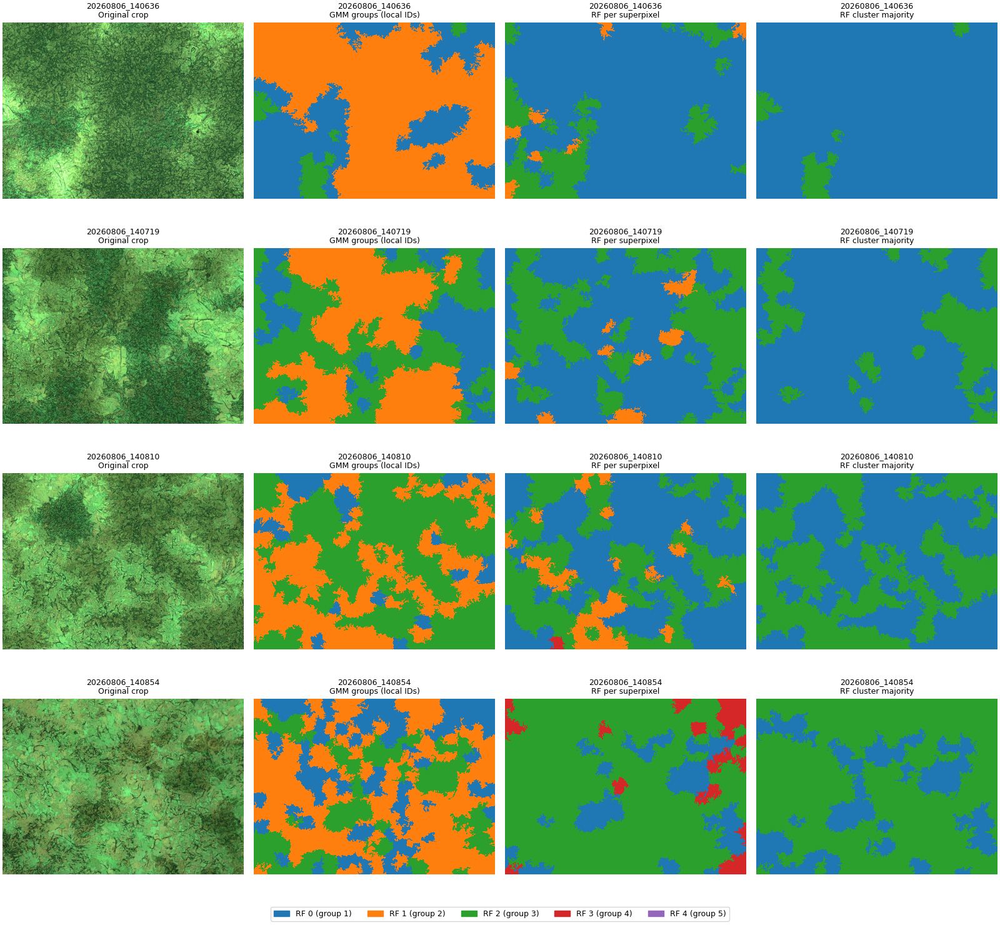

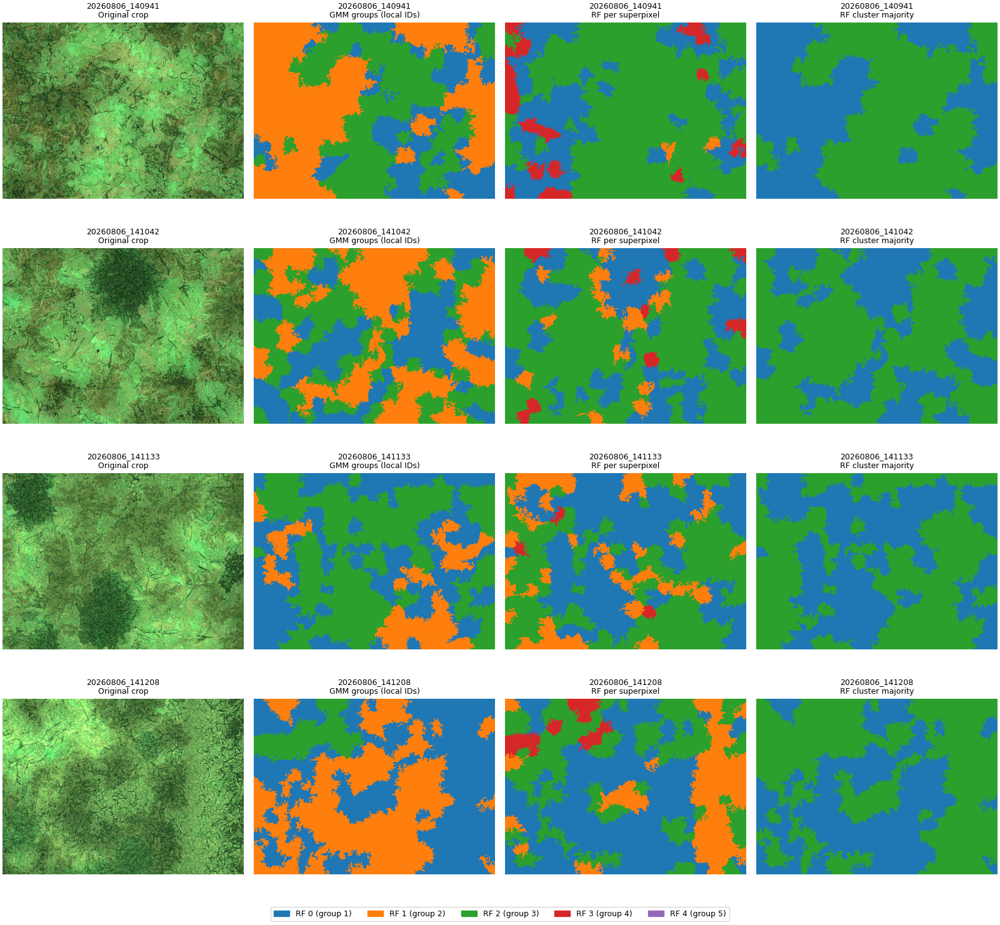

In [8]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

rf_colors = plt.cm.tab10(np.arange(len(rf_classes)))
rf_cmap = ListedColormap(rf_colors)
gmm_colors = plt.cm.tab10(np.arange(PRE_GMM_COMPONENTS))
gmm_cmap = ListedColormap(gmm_colors)
rf_legend = [Patch(color=color, label=f"RF {label} (group {rf_names.get(label, label)})")
             for label, color in zip(rf_classes, rf_colors)]

def rf_pixel_map(labels, segment_indices):
    values = np.full(len(labels), -1, dtype=int)
    for index, label in enumerate(rf_classes):
        values[labels == label] = index
    return np.ma.masked_less(values[segment_indices], 0)

for start in range(0, len(rf_records), 4):
    page = rf_records[start:start+4]
    fig, axes = plt.subplots(len(page), 4, figsize=(16, 3.7 * len(page)), squeeze=False, layout="constrained")
    for row_axes, record in zip(axes, page):
        name = f"image_{record['image_id']:04d}"
        directory = RF_RUN_DIR / "preprocessing" / name
        rf_image = np.load(directory / "image.npy", mmap_mode="r", allow_pickle=False)
        rf_segments = np.load(directory / "segments.npy", mmap_mode="r", allow_pickle=False)
        with np.load(RF_RESULT_DIR / f"{name}.npz", allow_pickle=False) as saved:
            label_indices = np.searchsorted(saved["labels"], rf_segments)
            raw_map = rf_pixel_map(saved["individual_labels"], label_indices)
            voted_map = rf_pixel_map(saved["stage1_labels"], label_indices)
            group_labels = np.full(len(saved["labels"]), -1, dtype=int)
        with np.load(RF_RUN_DIR / "gmm" / f"{name}.npz", allow_pickle=False) as saved:
            group_labels[saved["valid_indices"]] = saved["cluster_labels"]
        group_map = np.ma.masked_less(group_labels[label_indices], 0)
        row_axes[0].imshow(rf_image)
        row_axes[1].imshow(group_map, cmap=gmm_cmap, vmin=0, vmax=PRE_GMM_COMPONENTS-1, interpolation="nearest")
        row_axes[2].imshow(raw_map, cmap=rf_cmap, vmin=0, vmax=len(rf_classes)-1, interpolation="nearest")
        row_axes[3].imshow(voted_map, cmap=rf_cmap, vmin=0, vmax=len(rf_classes)-1, interpolation="nearest")
        for ax, title in zip(row_axes, ["Original crop", "GMM groups (local IDs)", "RF per superpixel", "RF cluster majority"]):
            ax.set_title(f"{record['name']}\n{title}", fontsize=9)
            ax.axis("off")
        del rf_image, rf_segments, label_indices, raw_map, voted_map, group_map
    fig.legend(handles=rf_legend, loc="lower center", ncol=len(rf_classes), fontsize=9)
    fig.get_layout_engine().set(rect=(0, .045, 1, .955), hspace=.10, wspace=.04)
    fig.savefig(OUTPUT_DIR / f"08_rf_classification_page_{start//4+1:02d}.png", dpi=150)
    plt.show()
    plt.close(fig)


## 9. Count the RF votes in each GMM cluster
Each panel is one image; each stacked bar is one GMM cluster. Colored segments show the fraction of member **superpixels** voting for each RF class. Text above the bar gives the winning raw RF label and its vote fraction. A large superpixel still contributes only one vote; final class area instead counts its pixels. Ties follow the production sorted-label rule. RF class names and colors match the preceding figures.

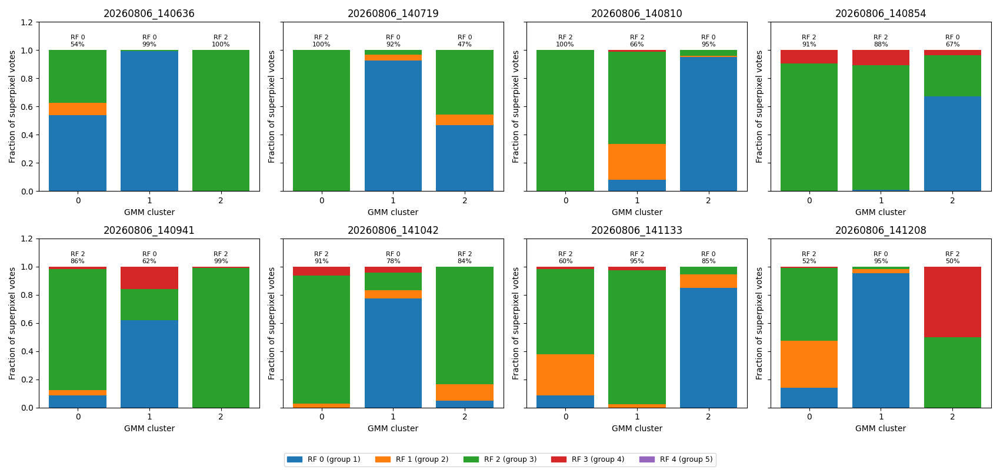

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey=True)
for ax, record in zip(axes.flat, rf_records):
    rows = rf_votes[rf_votes.image_id == record["image_id"]]
    table = rows.pivot(index="cluster_id", columns="rf_class", values="vote_fraction").reindex(columns=rf_classes, fill_value=0)
    bottom = np.zeros(len(table))
    for label, color in zip(rf_classes, rf_colors):
        values = table[label].to_numpy()
        ax.bar(table.index, values, bottom=bottom, color=color, label=f"RF {label}")
        bottom += values
    winners = rf_clusters[rf_clusters.image_id == record["image_id"]]
    for row in winners.itertuples(index=False):
        ax.text(row.cluster_id, 1.025, f"RF {row.stage1_label}\n{row.stage1_majority:.0%}", ha="center", fontsize=8)
    ax.set(title=record["name"], xlabel="GMM cluster", ylabel="Fraction of superpixel votes",
           xticks=table.index, ylim=(0, 1.2))
fig.legend(handles=rf_legend, loc="lower center", ncol=len(rf_classes), fontsize=9)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(OUTPUT_DIR / "09_rf_majority_votes.png", dpi=150)
plt.show()
plt.close(fig)


## 10. RF-class superpixels: eight images per class
Each figure is **one RF class across all eight images**, arranged in a consistent 2 × 4 grid. Only the superpixels assigned to that RF class **after pre-GMM cluster majority voting** retain their original colors; other pixels are white. The image order is the same in every figure. All five model classes are shown, including classes with no assigned superpixels. Titles report counts and fractions of the full cropped image area.

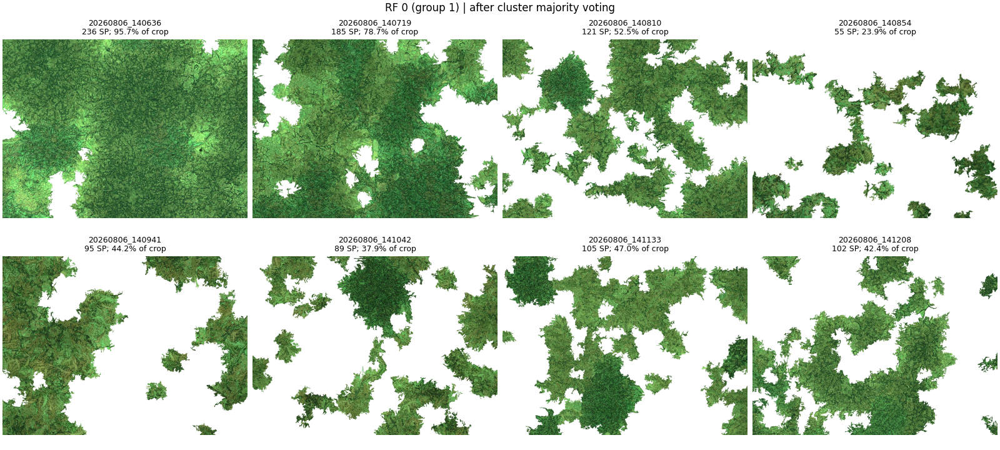

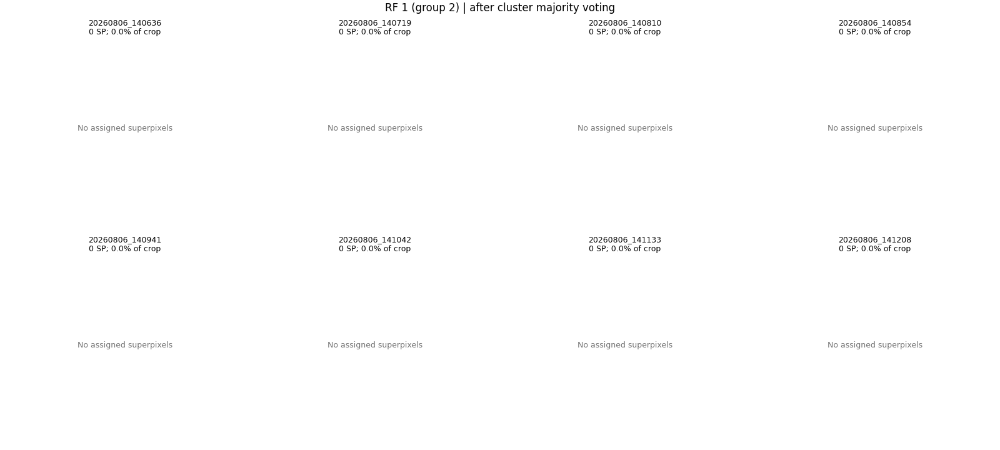

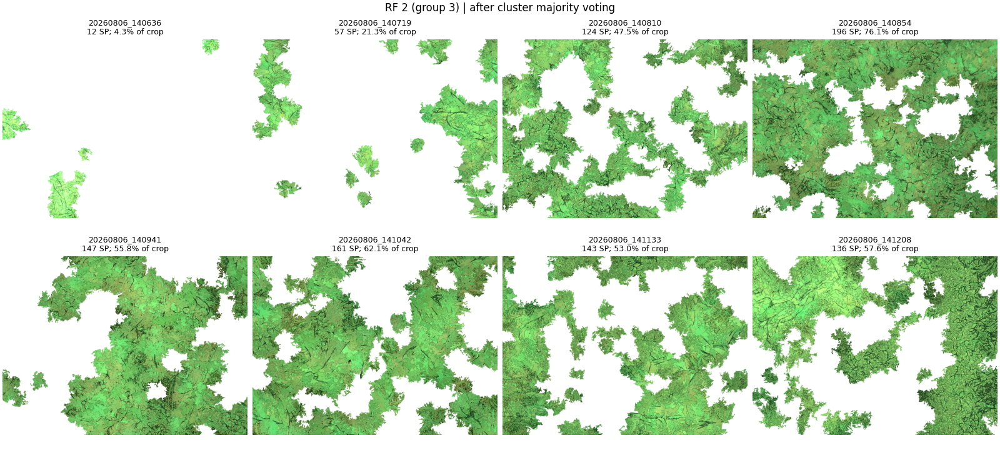

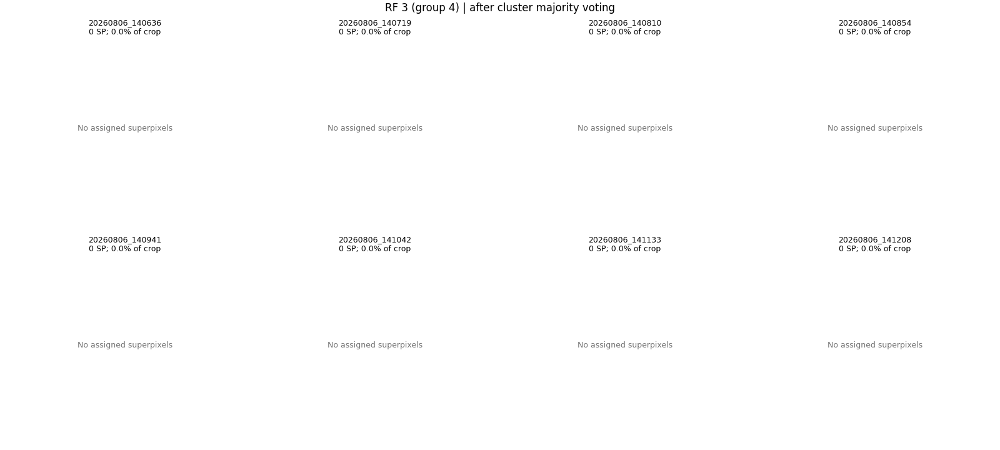

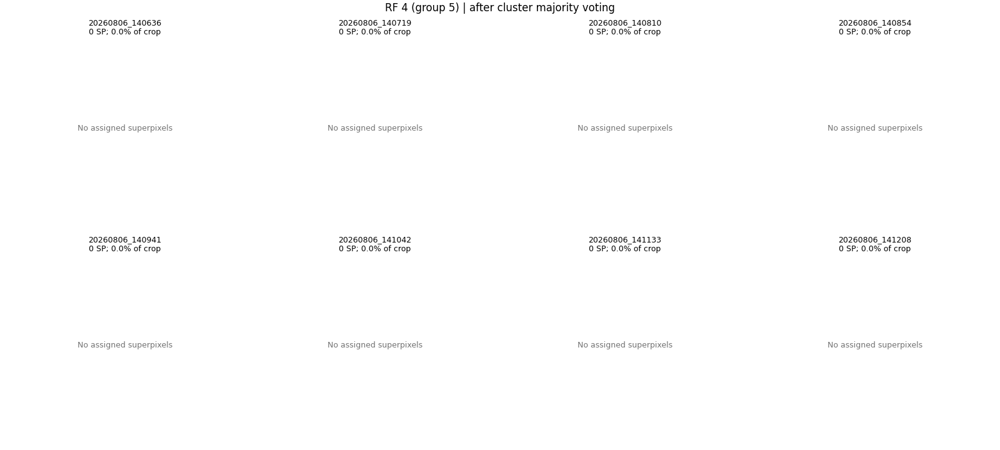

,N_superpixels,area_pixels
label,,
0,988,10971278
1,0,0
2,976,9811826
3,0,0
4,0,0


In [10]:
def show_superpixel_groups(record, labels, assignments, groups, title, output_path):
    """Show one image's original crop and each assigned group in original colors."""
    name = f"image_{record['image_id']:04d}"
    directory = RF_RUN_DIR / "preprocessing" / name
    original_image = np.load(directory / "image.npy", mmap_mode="r", allow_pickle=False)
    original_segments = np.load(directory / "segments.npy", mmap_mode="r", allow_pickle=False)
    if not np.array_equal(np.unique(original_segments), labels) or len(assignments) != len(labels):
        raise ValueError(f"Segment labels or assignments do not match: {name}")
    segment_indices = np.searchsorted(labels, original_segments)
    ncols = min(4, (len(groups) + 2) // 2)
    nrows = (len(groups) + 1 + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows),
                             squeeze=False, layout="constrained")
    axes.flat[0].imshow(original_image)
    axes.flat[0].set_title("Original crop")
    rows = []
    for ax, (label, caption) in zip(list(axes.flat)[1:], groups):
        selected = assignments == label
        mask = selected[segment_indices]
        view = np.full_like(original_image, 255)
        view[mask] = original_image[mask]
        ax.imshow(view)
        count, pixels = int(selected.sum()), int(mask.sum())
        ax.set_title(f"{caption}\n{count} SP; {pixels / mask.size:.1%} of crop", fontsize=10)
        if not count:
            ax.text(.5, .5, "No assigned superpixels", transform=ax.transAxes,
                    ha="center", va="center", color="0.45")
        rows.append({"image_id": record["image_id"], "name": record["name"], "label": label,
                     "N_superpixels": count, "area_pixels": pixels, "area_fraction": pixels / mask.size})
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(f"{record['name']} | {title}")
    fig.savefig(output_path, dpi=120)
    plt.show()
    plt.close(fig)
    return rows

def show_class_across_images(label, caption, result_dir, assignment_key, output_path):
    """Show one class in the same eight-image order used throughout the tutorial."""
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.2), layout="constrained")
    rows = []
    for ax, record in zip(axes.flat, rf_records):
        name = f"image_{record['image_id']:04d}"
        directory = RF_RUN_DIR / "preprocessing" / name
        original_image = np.load(directory / "image.npy", mmap_mode="r", allow_pickle=False)
        original_segments = np.load(directory / "segments.npy", mmap_mode="r", allow_pickle=False)
        with np.load(result_dir / f"{name}.npz", allow_pickle=False) as saved:
            labels, assignments = saved["labels"], saved[assignment_key]
        if not np.array_equal(np.unique(original_segments), labels) or len(assignments) != len(labels):
            raise ValueError(f"Segment labels or assignments do not match: {name}")
        selected = assignments == label
        mask = selected[np.searchsorted(labels, original_segments)]
        view = np.full_like(original_image, 255)
        view[mask] = original_image[mask]
        ax.imshow(view)
        count, pixels = int(selected.sum()), int(mask.sum())
        ax.set_title(f"{record['name']}\n{count} SP; {pixels / mask.size:.1%} of crop", fontsize=9)
        if not count:
            ax.text(.5, .5, "No assigned superpixels", transform=ax.transAxes,
                    ha="center", va="center", color="0.45", fontsize=9)
        ax.axis("off")
        rows.append({"image_id": record["image_id"], "name": record["name"], "label": label,
                     "N_superpixels": count, "area_pixels": pixels, "area_fraction": pixels / mask.size})
    fig.suptitle(caption)
    fig.savefig(output_path, dpi=120)
    plt.show()
    plt.close(fig)
    return rows

RF_CLASS_FIGURE_DIR = OUTPUT_DIR / "rf_class_superpixels" / "by_class"
RF_CLASS_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
rf_area_rows = []
for label in rf_classes:
    rf_area_rows.extend(show_class_across_images(
        label, f"RF {label} (group {rf_names.get(label, label)}) | after cluster majority voting",
        RF_RESULT_DIR, "stage1_labels", RF_CLASS_FIGURE_DIR / f"class_{label}.png"))
rf_class_areas = pd.DataFrame(rf_area_rows)
rf_class_areas.to_csv(RF_CLASS_FIGURE_DIR / "class_areas.csv", index=False)
display(rf_class_areas.groupby("label", sort=False)[["N_superpixels", "area_pixels"]].sum())


## 11. Additional GMM directly within each RF class
Pool the superpixels assigned to the same RF class across the eight images and fit one additional GMM per parent. This step selects rows from the **per-superpixel RF parent-label array**, without loading pre-RF GMM cluster IDs or using original-cluster boundaries. The RF parent labels remain the outputs of the earlier RF majority step; only additional-GMM grouping and assignment are independent of those earlier clusters.

Use the original 18 features, standardization, up to 10 PCs, full covariance, five initializations, regularization `1e-5` and seed 0. Each superpixel keeps its own additional-GMM prediction. No original-cluster majority voting or `apply_subclasses` is used, so one original cluster can split across several subclasses. The editable default is two components per present RF class. Outputs use a separate `rf_stage1_direct_subclasses` configuration to distinguish these results from previous cluster-majority experiments.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import json

present_classes = set(rf_clusters["stage1_label"].astype(str))
SUBCLASS_COMPONENTS = {label: 2 for label in rf_classes if label in present_classes}
SUBCLASS_CONFIG_NAME = "rf_stage1_direct_subclasses"
SUBCLASS_PCA_COMPONENTS = 10
SUBCLASS_RESULT_DIR = RF_RUN_DIR / "subclass_gmm" / SUBCLASS_CONFIG_NAME
SUBCLASS_LABEL_DIR = SUBCLASS_RESULT_DIR / "direct"
SUBCLASS_LABEL_DIR.mkdir(parents=True, exist_ok=True)
if not SUBCLASS_COMPONENTS:
    raise ValueError("No assigned RF classes are available for additional GMM.")

# Load only the small saved feature and RF-parent arrays; no pre-GMM cluster IDs.
image_features = {}
for record in rf_records:
    image_id = record["image_id"]
    name = f"image_{image_id:04d}"
    with np.load(RF_RUN_DIR / "features" / f"{name}.npz", allow_pickle=False) as saved:
        labels, values = saved["labels"], saved["features"].astype(np.float64)
        if saved["feature_names"].tolist() != FEATURE_NAMES:
            raise ValueError(f"Unexpected feature order: {name}")
    with np.load(RF_RESULT_DIR / f"{name}.npz", allow_pickle=False) as saved:
        if not np.array_equal(labels, saved["labels"]):
            raise ValueError(f"Feature and RF labels do not match: {name}")
        parents = saved["stage1_labels"]
    image_features[image_id] = {"labels": labels, "features": values, "parents": parents,
                                 "final": parents.astype("<U40", copy=True)}

summary_rows = []
for parent, count in SUBCLASS_COMPONENTS.items():
    arrays, identifiers = [], []
    for image_id, saved in image_features.items():
        indices = np.flatnonzero(saved["parents"] == parent)
        arrays.append(saved["features"][indices])
        identifiers.append(np.column_stack([np.full(len(indices), image_id), indices]))
    values, identifiers = np.vstack(arrays), np.vstack(identifiers).astype(int)
    if len(values) < max(count, 2) or not np.isfinite(values).all():
        raise ValueError(f"Not enough finite superpixel features for RF class {parent}.")
    scaled = StandardScaler().fit_transform(values)
    subclass_pca = PCA(n_components=min(SUBCLASS_PCA_COMPONENTS, *scaled.shape), random_state=0)
    transformed = subclass_pca.fit_transform(scaled)
    subclass_model = GaussianMixture(n_components=count, covariance_type="full", random_state=0,
                                      n_init=5, reg_covar=1e-5)
    children = subclass_model.fit_predict(transformed)
    probabilities = subclass_model.predict_proba(transformed)
    np.savez_compressed(SUBCLASS_RESULT_DIR / f"class_{parent}.npz",
                        image_ids=identifiers[:, 0], sp_indices=identifiers[:, 1],
                        subclass_labels=children, probabilities=probabilities, n_components=count,
                        pca_components=subclass_pca.n_components_,
                        explained_variance=subclass_pca.explained_variance_ratio_.sum())
    for image_id, saved in image_features.items():
        selected = identifiers[:, 0] == image_id
        saved["final"][identifiers[selected, 1]] = [f"{parent}_{child}" for child in children[selected]]
    summary_rows.extend({"parent_class": parent, "subclass": child,
                         "N_superpixels": int(np.count_nonzero(children == child))}
                        for child in range(count))
    print(f"RF {parent}: {len(values)} superpixels -> {count} direct subclasses", flush=True)

for image_id, saved in image_features.items():
    for parent in SUBCLASS_COMPONENTS:
        assert np.array_equal(np.char.startswith(saved["final"], parent + "_"), saved["parents"] == parent)
    np.savez_compressed(SUBCLASS_LABEL_DIR / f"image_{image_id:04d}.npz",
                        labels=saved["labels"], parent_labels=saved["parents"], final_labels=saved["final"])
(SUBCLASS_RESULT_DIR / "settings.json").write_text(json.dumps({
    "n_components": SUBCLASS_COMPONENTS, "pca_components": SUBCLASS_PCA_COMPONENTS,
    "parent_labels": "stage1_labels from the earlier RF step",
    "assignment": "direct per-superpixel GMM; no pre-GMM cluster IDs or cluster majority",
}, indent=2) + "\n", encoding="utf-8")
subclass_summary = pd.DataFrame(summary_rows)
subclass_summary.to_csv(SUBCLASS_RESULT_DIR / "subclass_summary.csv", index=False)
display(subclass_summary)
del image_features


,parent_class,subclass,N_superpixels
0,0,0,259
1,0,1,729
2,2,0,708
3,2,1,268


RF 0: 988 superpixels -> 2 direct subclasses
RF 2: 976 superpixels -> 2 direct subclasses


## 12. Direct subclasses: eight images per subclass
Each figure is **one additional-GMM subclass across all eight images**, in the same 2 × 4 order as section 10. Labels such as `0_1` mean RF parent 0 / additional-GMM subclass 1. Each superpixel keeps its own prediction; original pre-RF GMM clusters do not constrain these masks.

Subclasses with no members in an image are explicitly shown as empty. Each parent's subclass counts and pixel areas must sum to that parent's values in section 10. The final check cell shows these exact same saved assignments with all subclasses side by side for each image.

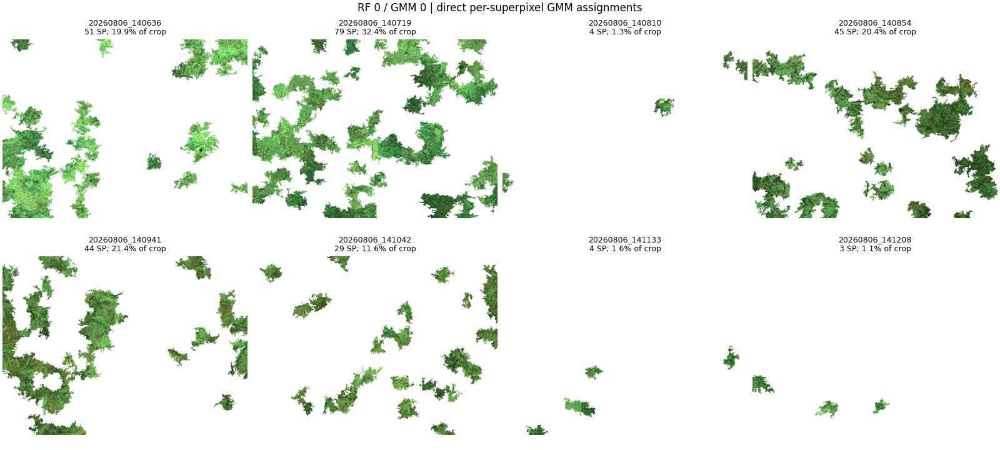

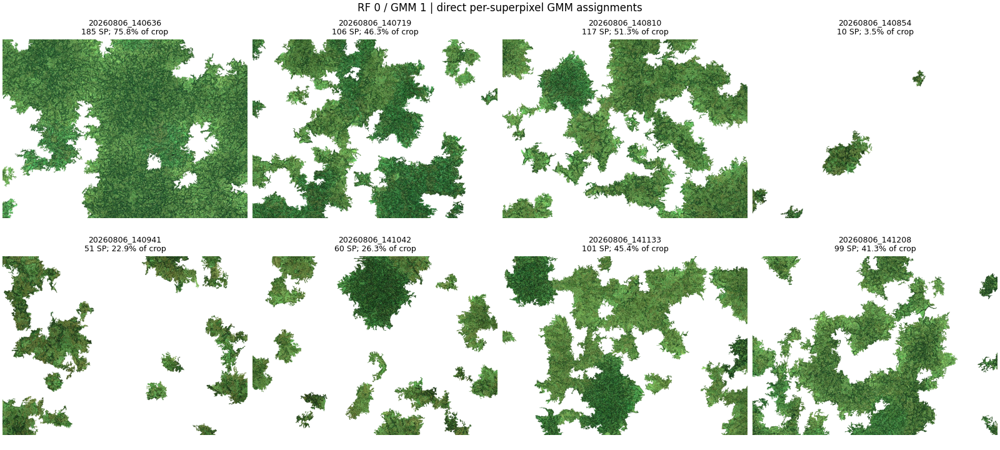

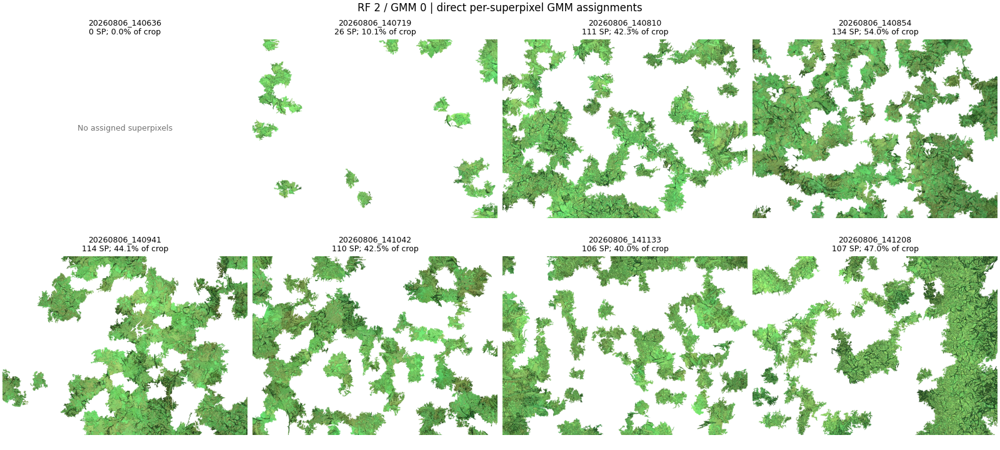

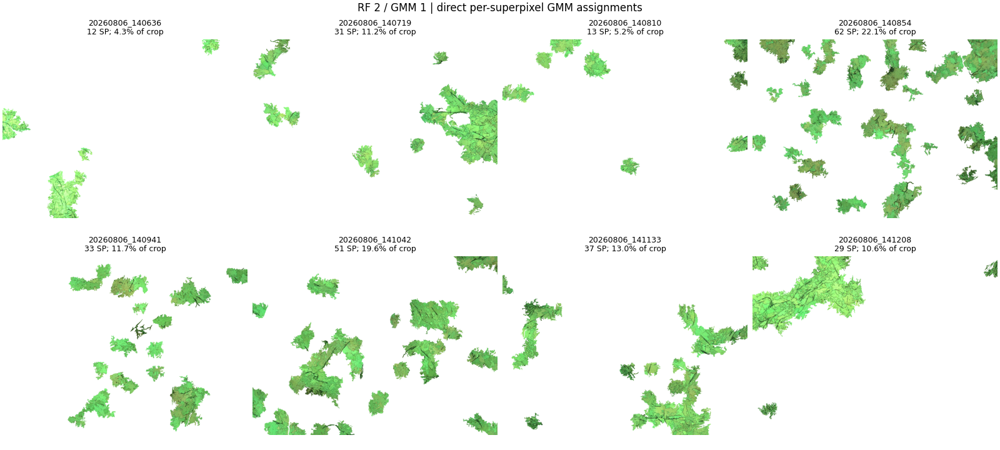

RF class grids: /home/kmanabe2403/dune/implement/outputs/tutorial_001/rf_class_superpixels/by_class
Direct subclass grids: /home/kmanabe2403/dune/implement/outputs/tutorial_001/rf_stage1_legacy_training/subclass_gmm/rf_stage1_direct_subclasses/direct/figures_by_class
Direct subclass partitions preserve every RF parent's superpixel and pixel counts.


In [12]:
SUBCLASS_FIGURE_DIR = SUBCLASS_LABEL_DIR / "figures_by_class"
SUBCLASS_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
subclass_groups = [(f"{parent}_{child}", f"RF {parent} / GMM {child}")
                   for parent, count in SUBCLASS_COMPONENTS.items() for child in range(count)]
subclass_area_rows = []
for label, caption in subclass_groups:
    subclass_area_rows.extend(show_class_across_images(
        label, f"{caption} | direct per-superpixel GMM assignments",
        SUBCLASS_LABEL_DIR, "final_labels", SUBCLASS_FIGURE_DIR / f"class_{label}.png"))
subclass_areas = pd.DataFrame(subclass_area_rows)
subclass_areas.to_csv(SUBCLASS_FIGURE_DIR / "subclass_areas.csv", index=False)
for row in rf_class_areas.itertuples(index=False):
    if row.label in SUBCLASS_COMPONENTS:
        parts = subclass_areas[(subclass_areas.image_id == row.image_id)
                               & subclass_areas.label.str.startswith(row.label + "_")]
        assert parts.area_pixels.sum() == row.area_pixels
        assert parts.N_superpixels.sum() == row.N_superpixels
print(f"RF class grids: {RF_CLASS_FIGURE_DIR}")
print(f"Direct subclass grids: {SUBCLASS_FIGURE_DIR}")
print("Direct subclass partitions preserve every RF parent's superpixel and pixel counts.")


## Appendix
### A. Maximum posterior probability
For each superpixel, GMM returns a probability for each component. The largest is its maximum posterior probability: `[0.80, 0.15, 0.05]` gives confidence 0.80 and cluster 0. The map below belongs to the **single-image 2D demo**, not the production RF run. Bright regions indicate more decisive assignments within that fitted model; this is not measured accuracy.

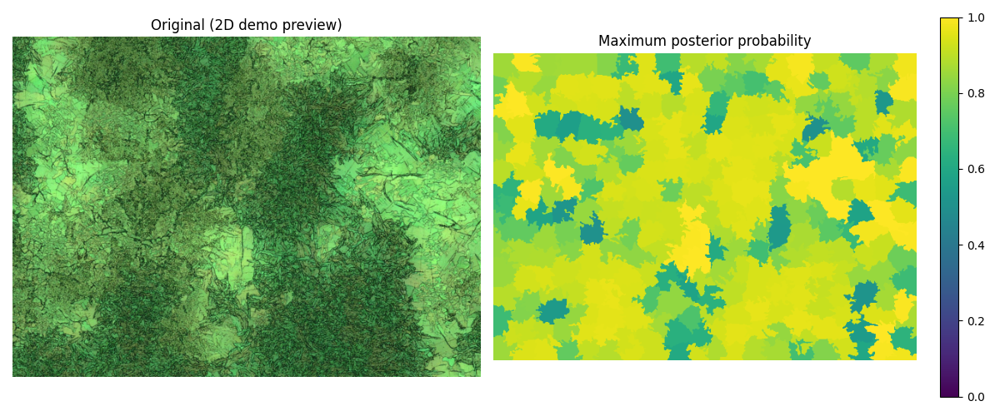

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Original (2D demo preview)")
im = axes[1].imshow(confidence_map, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Maximum posterior probability")
fig.colorbar(im, ax=axes[1], fraction=.046)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "10_maximum_posterior.png", dpi=150)
plt.show()
plt.close(fig)


### B. Saved RF model feature importance
The saved first-stage RF uses the original 18 features in its saved feature order, not 2D PCA coordinates. This plot shows its eight highest impurity-based feature importances. They summarize the trained model, not causal effects or held-out accuracy. The production feature extractor and fixed Lab reference are shared with training.

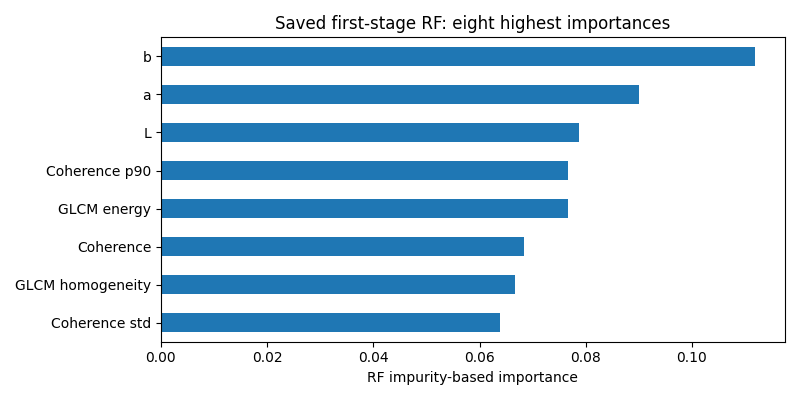

In [14]:
package = joblib.load(WORK_DIR / "data/models/rf_step1.pkl")
importance = pd.Series(package["model"].feature_importances_, index=package["feature_names"]).sort_values().tail(8)
fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax)
ax.set(xlabel="RF impurity-based importance", title="Saved first-stage RF: eight highest importances")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "11_rf_features.png", dpi=120)
plt.show()
plt.close(fig)


### C. RF feature compatibility: controlled comparison
The archived training feature function uses `rgb2gray`, whereas the earlier implementation used the RGB channel mean. Archived training also corrects pixel Lab maps before superpixel averaging, whereas the earlier implementation corrected pre-averaged values. These differences affect several texture features as well as numerical Lab means.

There is a separate reference mismatch: `color_reference.pkl` contains a different Lab reference from this saved `rf_step1.pkl`. The experiment therefore compares **current**, **legacy features with the same reference**, and **legacy features with the model's own reference**. All cases use the same eight full-resolution crops, SLIC segments and saved RF. No model is retrained. Fixed-GMM voting isolates the RF-input effect; refitted-GMM voting measures the end-to-end grouping/classification change. Cluster IDs from different GMM fits are not compared directly.

A changed prediction is not proof of improved accuracy without ground-truth labels. Both legacy modes were checked against the actual archived feature function on the first full-resolution image, with exact feature equality. The tables below and the eight comparison figures under `feature_compatibility/figures/` preserve the earlier baseline. Main tutorial results above use the legacy/model-reference condition.

In [15]:
COMPARISON_DIR = OUTPUT_DIR / "feature_compatibility"
comparison_summary = pd.read_csv(COMPARISON_DIR / "summary.csv")
comparison_per_image = pd.read_csv(COMPARISON_DIR / "rf_changes.csv")
display(comparison_summary)
display(comparison_per_image)
print(f"Eight before/after RF comparison figures: {COMPARISON_DIR / 'figures'}")


,case,N_superpixels,individual_changed,fixed_gmm_majority_changed,refitted_gmm_majority_changed,mean_changed_pixel_percent
0,legacy_model_reference,1964,277,203,237,12.465549
1,legacy_same_reference,1964,247,203,237,12.465549


,case,image_id,name,N_superpixels,individual_changed,fixed_gmm_majority_changed,refitted_gmm_majority_changed,fixed_gmm_changed_pixel_percent,refitted_gmm_changed_pixel_percent
0,legacy_same_reference,0,20260806_140636,248,20,0,4,0.000000,1.223109
1,legacy_model_reference,0,20260806_140636,248,20,0,4,0.000000,1.223109
2,legacy_same_reference,1,20260806_140719,242,45,97,96,39.170819,38.908644
3,legacy_model_reference,1,20260806_140719,242,46,97,96,39.170819,38.908644
4,legacy_same_reference,2,20260806_140810,245,35,0,2,0.000000,0.685942
5,legacy_model_reference,2,20260806_140810,245,38,0,2,0.000000,0.685942
6,legacy_same_reference,3,20260806_140854,251,26,0,16,0.000000,7.827089
7,legacy_model_reference,3,20260806_140854,251,28,0,16,0.000000,7.827089
8,legacy_same_reference,4,20260806_140941,242,21,0,3,0.000000,1.313567
9,legacy_model_reference,4,20260806_140941,242,33,0,3,0.000000,1.313567


Eight before/after RF comparison figures: /home/kmanabe2403/dune/implement/outputs/tutorial_001/feature_compatibility/figures


### Try another setting
Change `PRE_GMM_COMPONENTS` in the paths/settings cell to update both the educational GMM and pre-RF GMM, then rerun downstream cells. The archived implementation's explicit setting is 3; no per-image counts for the eight-image implementation run were found. The number of component panels, colors, area bars and RF votes adapts to the shared count.

For the 2D demo, change `IMAGE_PATH` and rerun downstream cells. This does not change the eight RF images. RF grouping keeps up to 15 PCs, matching production, while the educational GMM stays in 2D. For RF image selection, change the paths and `RF_CONFIG` together. Choose a new `OUTPUT_DIR` when comparing runs; rerunning overwrites the selected tutorial outputs.

## Final check. All subclasses side by side for each image
Each image gets its original crop and all direct per-superpixel subclass masks. This cell reads the **same saved labels as section 12**; it only changes the arrangement from class-by-class to image-by-image. It does not fit another model or vote over original clusters.

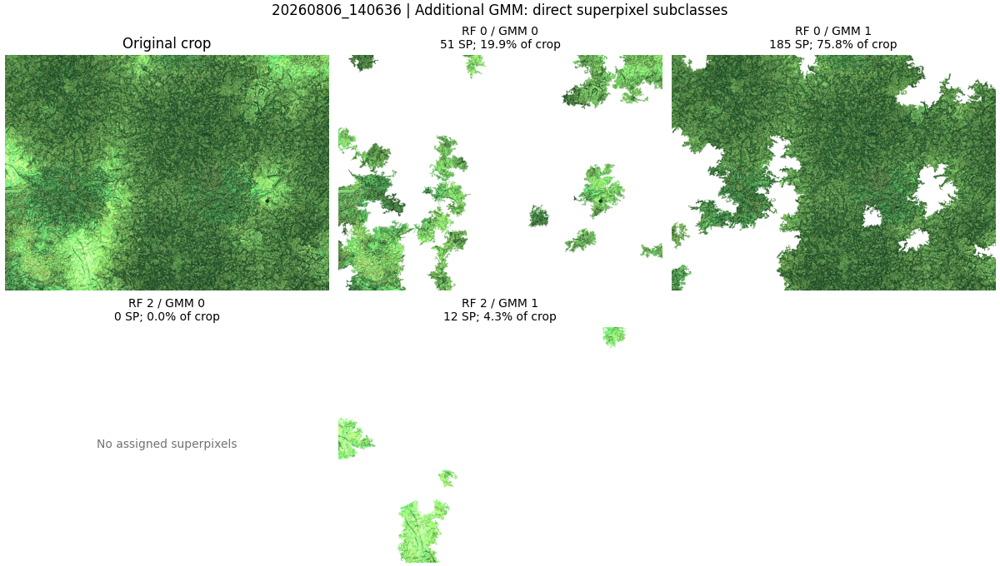

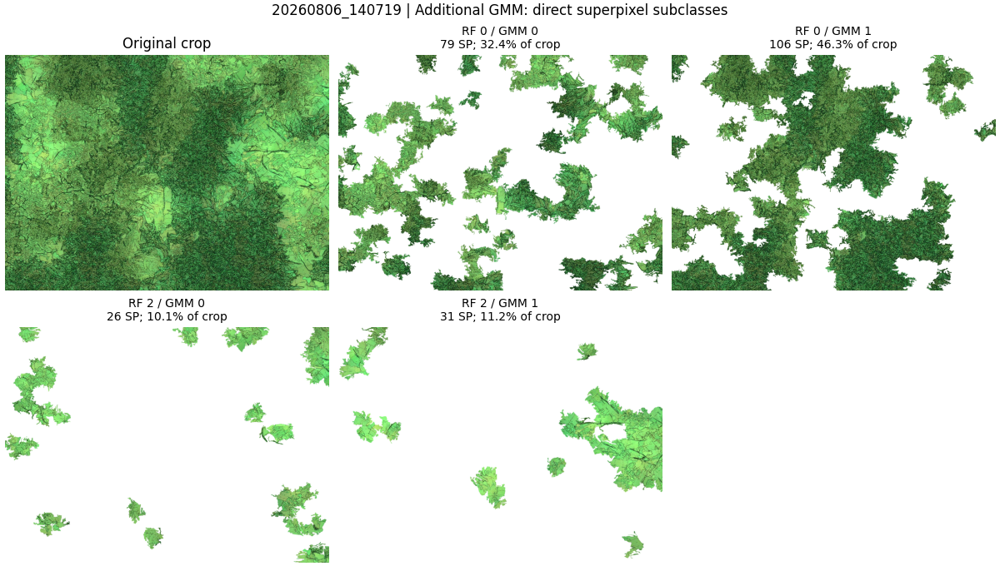

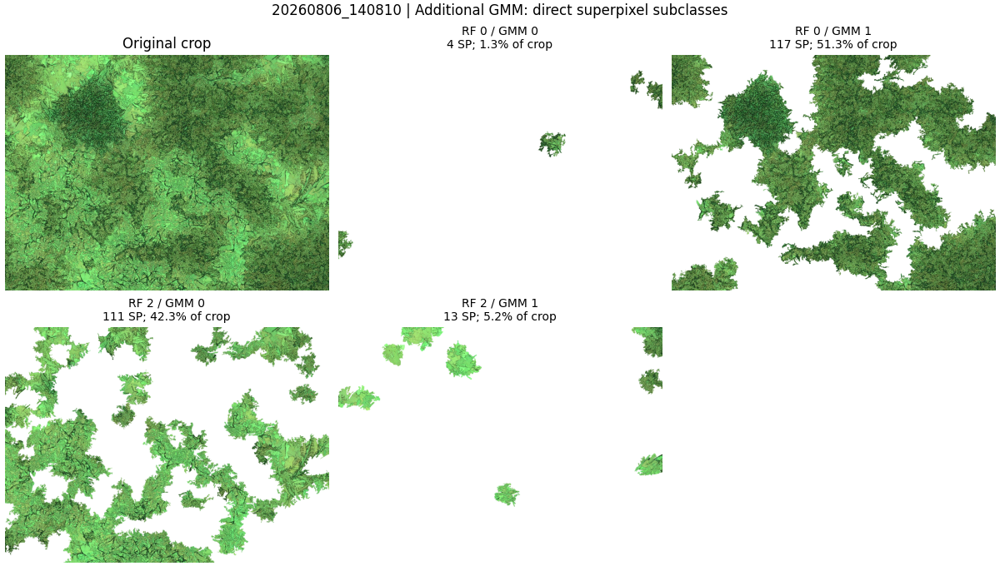

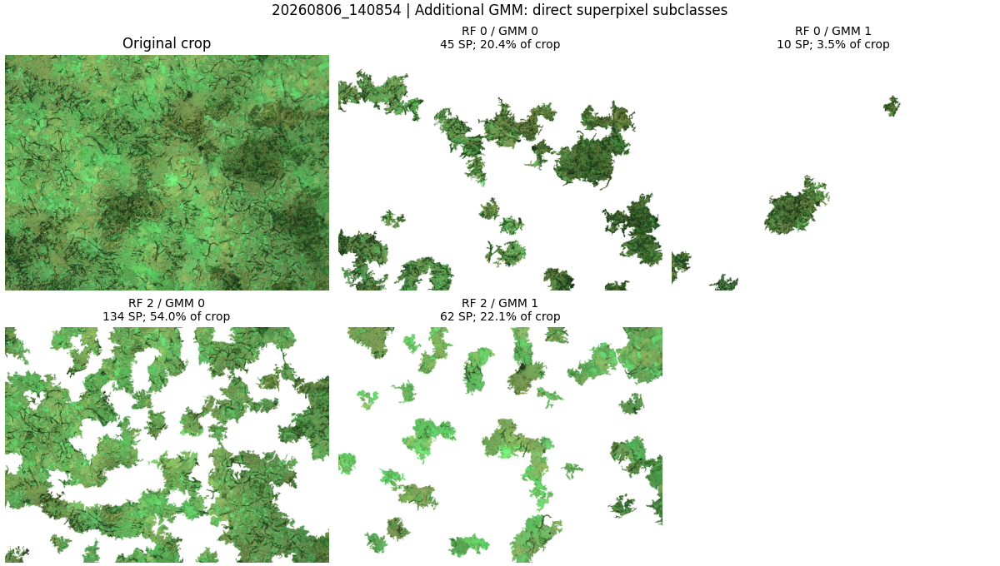

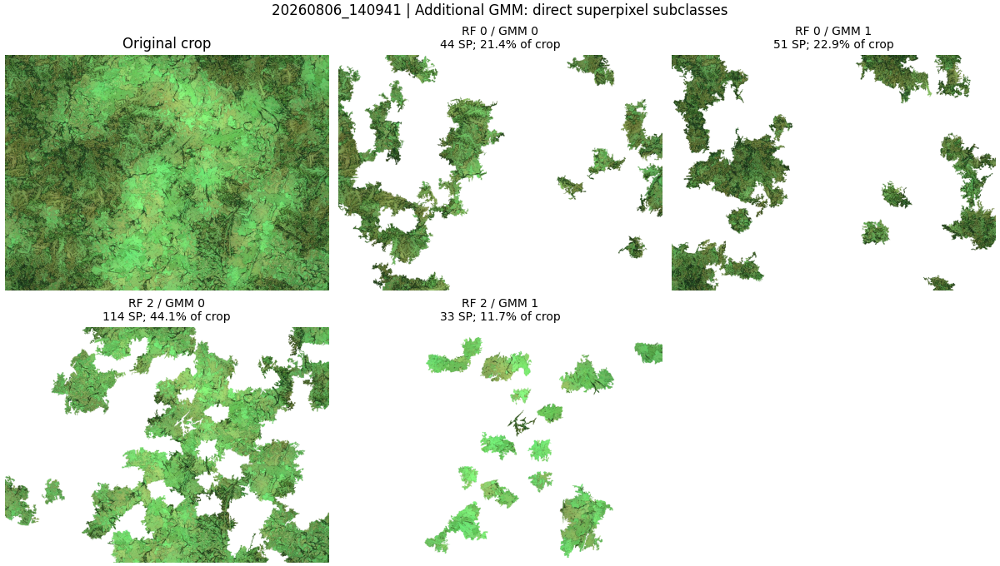

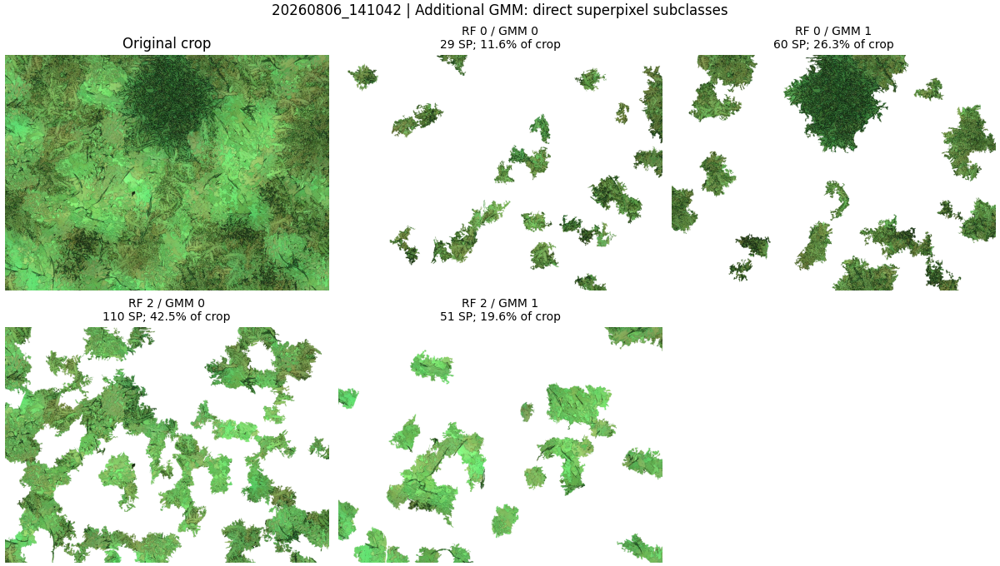

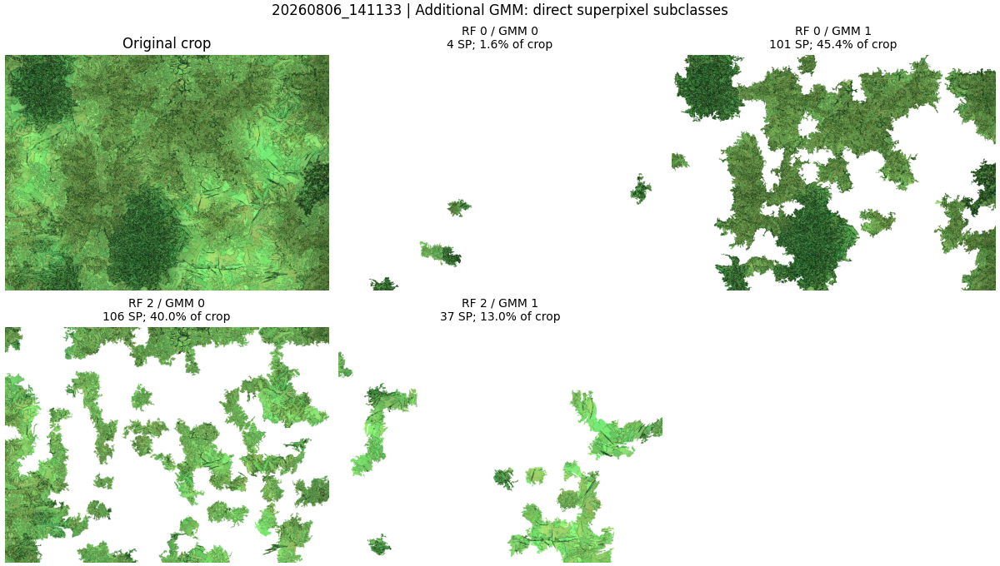

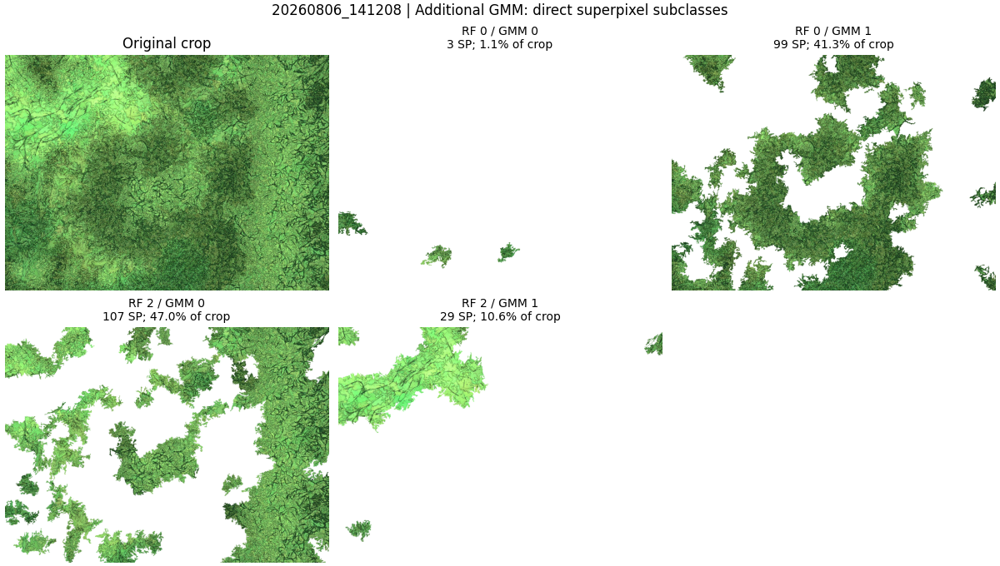

Class-by-class and image-by-image displays use exactly the same subclass labels and areas.
Eight image-by-image checks: /home/kmanabe2403/dune/implement/outputs/tutorial_001/rf_stage1_legacy_training/subclass_gmm/rf_stage1_direct_subclasses/per_image_check


In [16]:
DIRECT_CHECK_FIGURE_DIR = SUBCLASS_RESULT_DIR / "per_image_check"
DIRECT_CHECK_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
direct_area_rows = []
for record in rf_records:
    name = f"image_{record['image_id']:04d}"
    with np.load(SUBCLASS_LABEL_DIR / f"{name}.npz", allow_pickle=False) as saved:
        direct_area_rows.extend(show_superpixel_groups(
            record, saved["labels"], saved["final_labels"], subclass_groups,
            "Additional GMM: direct superpixel subclasses", DIRECT_CHECK_FIGURE_DIR / f"{name}.png"))
direct_areas = pd.DataFrame(direct_area_rows)
direct_areas.to_csv(DIRECT_CHECK_FIGURE_DIR / "direct_areas.csv", index=False)
keys = ["image_id", "label"]
pd.testing.assert_frame_equal(
    direct_areas.sort_values(keys).reset_index(drop=True),
    subclass_areas.sort_values(keys).reset_index(drop=True))
print("Class-by-class and image-by-image displays use exactly the same subclass labels and areas.")
print(f"Eight image-by-image checks: {DIRECT_CHECK_FIGURE_DIR}")
